# Ajuste fino da IA com os vídeos do projeto
Rode as células **uma de cada vez, na ordem**. Cada etapa salva o resultado no Drive, então se a sessão cair basta rodar de novo a partir da célula 1.

In [ ]:
from google.colab import drive

drive.mount("/content/drive")
!pip install -q ultralytics

Mounted at /content/drive


In [ ]:
from pathlib import Path

PASTA_BASE = Path("/content/drive/MyDrive/safe_evidence_ia")
PASTA_VIDEOS = PASTA_BASE / "videos-proprios" / "videos"
ARQUIVO_TRECHOS = PASTA_VIDEOS / "trechos.csv"
PESOS_ATUAIS = PASTA_BASE / "melhor.pt"
PESOS_NOVOS = PASTA_BASE / "melhor_v4.pt"
PASTA_SAIDA = PASTA_BASE / "finetune"
PASTA_QUADROS = PASTA_SAIDA / "quadros"
PASTA_DATASET = Path("/content/dataset_proprio")

# Dataset publico RWF-2000 (Hugging Face): clipes de 5 s de cameras de vigilancia
REPOSITORIO_RWF = "DanJoshua/RWF-2000"  # licenca MIT; arquivo unico de ~12 GB
ARQUIVO_RWF = "RWF-2000.tar.gz"
PASTA_RWF = Path("/content/rwf2000")
PASTA_QUADROS_RWF = Path("/content/rwf_quadros")
FRACAO_VALIDACAO_RWF = 0.5  # metade das fontes do val vira validacao, metade teste

# Opcional: pasta com quadros do XD-Violence no formato train/<classe>/*.jpg.
# Misturar evita que o modelo esqueça o que já aprendeu.
PASTA_DATASET_XD = None
QUADROS_XD_POR_CLASSE = 0  # 0 = nao misturar XD (o RWF-2000 substitui)

# Nomes dos arquivos de vídeo (como estão na pasta e no trechos.csv).
# Todos os outros vídeos vão para o treino.
VIDEOS_TESTE = ["esp2.mp4", "WhatsApp Video 2026-11-05 at 20.12.45.mp4", "IMG_0861.MOV"]
VIDEOS_VALIDACAO = []

QUADROS_POR_SEGUNDO = 4
TAMANHO_IMAGEM = 224
# Videos de celular em pe: "quadrado" corta o centro (pessoas maiores); "faixas" mantem a cena toda com tarjas pretas
MODO_VIDEO_VERTICAL = "quadrado"
MARGEM_S = 0.5
LIMIAR_QUADRO = 0.6276
REPETICOES_PROPRIOS = 4
RAZAO_NORMAL_PARA_VIOLENCIA = 1.5
EPOCAS = 12
TAXA_APRENDIZADO = 1e-4
CAMADAS_CONGELADAS = 0  # com milhares de quadros variados da pra treinar o modelo todo
DROPOUT = 0.2
SEMENTE = 42

In [ ]:
import csv
from dataclasses import dataclass

TIPOS_VALIDOS = {"violencia", "ignorar", "normal"}
EXTENSOES_VIDEO = {".mp4", ".mov", ".avi", ".mkv"}


@dataclass(frozen=True)
class Trecho:
    arquivo: str
    inicio_s: float
    fim_s: float
    tipo: str


def tempo_em_segundos(texto):
    segundos = 0.0
    for parte in texto.strip().split(":"):
        segundos = segundos * 60 + float(parte)
    return segundos


def interpretar_linha(colunas):
    if len(colunas) < 4:
        raise ValueError("faltam colunas (arquivo,inicio,fim,tipo)")
    inicio_s = tempo_em_segundos(colunas[1])
    fim_s = tempo_em_segundos(colunas[2])
    tipo = colunas[3].strip().lower().split()[0]
    if tipo not in TIPOS_VALIDOS:
        raise ValueError(f"tipo '{tipo}' invalido (use violencia, ignorar ou normal)")
    if fim_s <= inicio_s:
        raise ValueError(f"fim ({colunas[2].strip()}) deve ser maior que o inicio ({colunas[1].strip()})")
    return Trecho(colunas[0].strip(), inicio_s, fim_s, tipo)


def linha_vazia_ou_cabecalho(colunas):
    return not "".join(colunas).strip() or colunas[0].strip().lower() == "arquivo"


def ler_trechos(caminho):
    trechos, erros = [], []
    with open(caminho, encoding="utf-8-sig") as arquivo:
        for numero, colunas in enumerate(csv.reader(arquivo), start=1):
            if linha_vazia_ou_cabecalho(colunas):
                continue
            try:
                trechos.append(interpretar_linha(colunas))
            except ValueError as erro:
                erros.append(f"linha {numero}: {erro}")
    if erros:
        raise ValueError("Corrija o trechos.csv:\n" + "\n".join(erros))
    return list(dict.fromkeys(trechos))


def nome_sem_extensao(nome):
    for extensao in EXTENSOES_VIDEO:
        if nome.lower().endswith(extensao):
            return nome[: -len(extensao)]
    return nome


def localizar_video(nome, pasta):
    for caminho in pasta.iterdir():
        if caminho.suffix.lower() not in EXTENSOES_VIDEO:
            continue
        if nome_sem_extensao(caminho.name).lower() == nome_sem_extensao(nome).lower():
            return caminho
    return None


def agrupar_por_video(trechos, pasta_videos):
    por_video, ausentes = {}, []
    for trecho in trechos:
        video = localizar_video(trecho.arquivo, pasta_videos)
        if video is None:
            ausentes.append(trecho.arquivo)
        else:
            por_video.setdefault(video, []).append(trecho)
    if ausentes:
        raise FileNotFoundError("Videos nao encontrados na pasta: " + ", ".join(sorted(set(ausentes))))
    return por_video


trechos_por_video = agrupar_por_video(ler_trechos(ARQUIVO_TRECHOS), PASTA_VIDEOS)

for video, trechos in sorted(trechos_por_video.items(), key=lambda item: item[0].name):
    violentos = [t for t in trechos if t.tipo == "violencia"]
    segundos = sum(t.fim_s - t.inicio_s for t in violentos)
    print(f"{video.name:55s} {len(violentos):2d} trechos de violencia ({segundos:.0f} s)")

IMG_0861.MOV                                             5 trechos de violencia (19 s)
IMG_0888.MOV                                             2 trechos de violencia (27 s)
IMG_0889.MOV                                             0 trechos de violencia (0 s)
WhatsApp Video 2026-11-05 at 20.11.31.mp4                0 trechos de violencia (0 s)
WhatsApp Video 2026-11-05 at 20.12.34.mp4                0 trechos de violencia (0 s)
WhatsApp Video 2026-11-05 at 20.12.45.mp4                6 trechos de violencia (27 s)
esp1.mp4                                                 1 trechos de violencia (4 s)
esp2.mp4                                                 1 trechos de violencia (4 s)


In [ ]:
import json
import os
import random
import shutil
import subprocess
from dataclasses import dataclass


@dataclass(frozen=True)
class QuadroRotulado:
    caminho: Path
    classe: str
    video: str
    instante_s: float


def dentro_do_trecho(instante_s, trecho, margem_s=0.0):
    return trecho.inicio_s - margem_s <= instante_s <= trecho.fim_s + margem_s


def rotular_instante(instante_s, trechos):
    violentos = [t for t in trechos if t.tipo == "violencia"]
    if any(dentro_do_trecho(instante_s, t) for t in trechos if t.tipo == "ignorar"):
        return None
    if any(dentro_do_trecho(instante_s, t) for t in violentos):
        return "violencia"
    if any(dentro_do_trecho(instante_s, t, MARGEM_S) for t in violentos):
        return None
    return "normal"


def dimensoes_exibidas(video):
    saida = subprocess.run(
        ["ffprobe", "-v", "error", "-select_streams", "v:0",
         "-show_entries", "stream=width,height:stream_side_data=rotation", "-of", "json", str(video)],
        capture_output=True, text=True, check=True,
    ).stdout
    fluxo = json.loads(saida)["streams"][0]
    rotacao = next((int(d["rotation"]) for d in fluxo.get("side_data_list", []) if "rotation" in d), 0)
    largura, altura = fluxo["width"], fluxo["height"]
    return (altura, largura) if abs(rotacao) % 180 == 90 else (largura, altura)


def video_vertical(video):
    largura, altura = dimensoes_exibidas(video)
    return altura > largura


def filtro_de_quadros(video):
    reducao = f"scale={TAMANHO_IMAGEM}:{TAMANHO_IMAGEM}"
    if video_vertical(video) and MODO_VIDEO_VERTICAL == "quadrado":
        return f"fps={QUADROS_POR_SEGUNDO},crop=iw:iw:0:(ih-iw)/2,{reducao}"
    # Mesmo formato da ESP32-CAM: 640x480 (com tarjas pretas se o video nao for 4:3)
    return (
        f"fps={QUADROS_POR_SEGUNDO},"
        "scale=640:480:force_original_aspect_ratio=decrease,"
        f"pad=640:480:(ow-iw)/2:(oh-ih)/2,{reducao}"
    )


def pasta_dos_quadros(video, pasta_quadros):
    modo = MODO_VIDEO_VERTICAL if video_vertical(video) else "horizontal"
    return pasta_quadros / f"{video.stem}__{modo}"


def extrair_quadros(video, pasta_quadros):
    pasta_do_video = pasta_dos_quadros(video, pasta_quadros)
    if not any(pasta_do_video.glob("*.jpg")):
        pasta_do_video.mkdir(parents=True, exist_ok=True)
        subprocess.run(
            ["ffmpeg", "-v", "error", "-y", "-i", str(video), "-vf", filtro_de_quadros(video),
             "-q:v", "5", str(pasta_do_video / "%05d.jpg")],
            check=True,
        )
    return sorted(pasta_do_video.glob("*.jpg"))


def instante_do_quadro(caminho):
    return (int(caminho.stem) - 1) / QUADROS_POR_SEGUNDO


def rotular_video(video, trechos, pasta_quadros):
    quadros = []
    for caminho in extrair_quadros(video, pasta_quadros):
        instante_s = instante_do_quadro(caminho)
        classe = rotular_instante(instante_s, trechos)
        if classe is not None:
            quadros.append(QuadroRotulado(caminho, classe, video.stem, instante_s))
    return quadros


def divisao_do_video(video):
    if video.name.lower() in {nome.lower() for nome in VIDEOS_TESTE}:
        return "test"
    if video.name.lower() in {nome.lower() for nome in VIDEOS_VALIDACAO}:
        return "val"
    return "train"


def equilibrar(quadros, razao_normal_para_violencia):
    violentos = [q for q in quadros if q.classe == "violencia"]
    normais = [q for q in quadros if q.classe == "normal"]
    limite = int(len(violentos) * razao_normal_para_violencia)
    if violentos and len(normais) > limite:
        normais = random.Random(SEMENTE).sample(normais, limite)
    return violentos + normais


def conferir_divisoes(quadros_por_divisao):
    for divisao, quadros in quadros_por_divisao.items():
        total = {c: sum(q.classe == c for q in quadros) for c in ("normal", "violencia")}
        print(f"{divisao:5s} normal={total['normal']:5d}  violencia={total['violencia']:5d}")
        if total["violencia"] == 0 or total["normal"] == 0:
            print(f"  ATENCAO: '{divisao}' ficou sem uma das classes. Ajuste VIDEOS_TESTE/VIDEOS_VALIDACAO.")


def montar_quadros_por_divisao():
    quadros_por_divisao = {"train": [], "val": [], "test": []}
    for video, trechos in sorted(trechos_por_video.items(), key=lambda item: item[0].name):
        print("extraindo", video.name)
        quadros_por_divisao[divisao_do_video(video)] += rotular_video(video, trechos, PASTA_QUADROS)
    return quadros_por_divisao


def gravar_dataset(quadros_por_divisao, nome_da_classe):
    shutil.rmtree(PASTA_DATASET, ignore_errors=True)
    for divisao, quadros in quadros_por_divisao.items():
        repeticoes = REPETICOES_PROPRIOS if divisao == "train" else 1
        for quadro in quadros:
            pasta = PASTA_DATASET / divisao / nome_da_classe[quadro.classe]
            pasta.mkdir(parents=True, exist_ok=True)
            for repeticao in range(repeticoes):
                destino = pasta / f"{quadro.video}_{quadro.caminho.stem}_r{repeticao}.jpg"
                shutil.copy(quadro.caminho, destino)


def tem_quadros(pasta):
    return pasta.is_dir() and any(pasta.glob("*.jpg"))


def procurar_quadros_xd(pasta_base, nome_da_classe, profundidade_maxima=3):
    pastas_ignoradas = {PASTA_SAIDA.name, "videos-proprios"}
    for raiz, subpastas, _ in os.walk(pasta_base):
        subpastas[:] = [p for p in subpastas if p not in pastas_ignoradas]
        if len(Path(raiz).relative_to(pasta_base).parts) > profundidade_maxima:
            subpastas.clear()
        candidata = Path(raiz) / "train"
        if all(tem_quadros(candidata / nome) for nome in nome_da_classe.values()):
            return candidata.parent
    return None


def misturar_quadros_externos(origem_por_classe, quadros_por_classe, prefixo):
    for classe, origem in origem_por_classe.items():
        quadros = sorted(origem.glob("*.jpg"))
        sorteados = random.Random(SEMENTE).sample(quadros, min(quadros_por_classe, len(quadros)))
        destino = PASTA_DATASET / "train" / classe
        destino.mkdir(parents=True, exist_ok=True)
        for numero, caminho in enumerate(sorteados):
            shutil.copy(caminho, destino / f"{prefixo}_{numero:05d}.jpg")
        print(f"  {prefixo}: {len(sorteados)} quadros em '{classe}'")


def misturar_quadros_xd(nome_da_classe, pasta_xd):
    if pasta_xd is None or QUADROS_XD_POR_CLASSE == 0:
        return
    print("Misturando quadros do XD-Violence de", pasta_xd)
    origem_por_classe = {nome: Path(pasta_xd) / "train" / nome for nome in nome_da_classe.values()}
    misturar_quadros_externos(origem_por_classe, QUADROS_XD_POR_CLASSE, "xd")

### RWF-2000 completo


In [ ]:
from concurrent.futures import ThreadPoolExecutor

from huggingface_hub import hf_hub_download

PASTA_CLIPES_RWF = PASTA_RWF / "RWF-2000"


def existem_clipes(divisao):
    return any((PASTA_CLIPES_RWF / divisao).rglob("*.avi"))


def baixar_rwf():
    if existem_clipes("train") and existem_clipes("val"):
        return
    PASTA_RWF.mkdir(parents=True, exist_ok=True)
    arquivo = hf_hub_download(REPOSITORIO_RWF, ARQUIVO_RWF, repo_type="dataset", local_dir=str(PASTA_RWF / "_baixado"))
    # alguns clipes tem nome longo demais para o Linux; sao ignorados
    subprocess.run(["tar", "-xzf", arquivo, "-C", str(PASTA_RWF), "RWF-2000"], stderr=subprocess.DEVNULL)


def classe_do_clipe_rwf(clipe):
    return "normal" if "nonfight" in clipe.parent.name.lower() else "violencia"


def origem_do_clipe(clipe):
    return clipe.stem.rsplit("_", 1)[0]


def separar_validacao_e_teste(clipes):
    origens = sorted({origem_do_clipe(c) for c in clipes})
    random.Random(SEMENTE).shuffle(origens)
    origens_da_validacao = set(origens[: int(len(origens) * FRACAO_VALIDACAO_RWF)])
    validacao = [c for c in clipes if origem_do_clipe(c) in origens_da_validacao]
    teste = [c for c in clipes if origem_do_clipe(c) not in origens_da_validacao]
    return validacao, teste


def planejar_clipes():
    clipes_treino = sorted((PASTA_CLIPES_RWF / "train").rglob("*.avi"))
    clipes_val = sorted((PASTA_CLIPES_RWF / "val").rglob("*.avi"))
    validacao, teste = separar_validacao_e_teste(clipes_val)
    divisoes = {"train": clipes_treino, "val": validacao, "test": teste}
    plano = []
    for divisao, clipes in divisoes.items():
        for clipe in clipes:
            plano.append((len(plano), divisao, classe_do_clipe_rwf(clipe), clipe))
    return plano


def extrair_clipe(item):
    indice, divisao, classe, clipe = item
    pasta = PASTA_QUADROS_RWF / divisao / classe
    pasta.mkdir(parents=True, exist_ok=True)
    if not any(pasta.glob(f"{indice:05d}_*.jpg")):
        subprocess.run(
            ["ffmpeg", "-v", "error", "-y", "-i", str(clipe), "-vf", filtro_de_quadros(clipe),
             "-q:v", "5", str(pasta / f"{indice:05d}_%03d.jpg")],
            check=False,
        )


baixar_rwf()
plano_rwf = planejar_clipes()
contagem = {}
for _, divisao, classe, _ in plano_rwf:
    contagem[(divisao, classe)] = contagem.get((divisao, classe), 0) + 1
print("clipes por divisao/classe:", contagem)
assert plano_rwf and all(contagem.get((d, c)) for d in ("train", "val", "test") for c in ("normal", "violencia"))

with ThreadPoolExecutor(max_workers=4) as executor:
    list(executor.map(extrair_clipe, plano_rwf))
print("quadros extraidos em", PASTA_QUADROS_RWF)

clipes por divisao/classe: {('train', 'violencia'): 780, ('train', 'normal'): 800, ('val', 'violencia'): 90, ('val', 'normal'): 103, ('test', 'violencia'): 110, ('test', 'normal'): 97}
quadros extraidos em /content/rwf_quadros


In [ ]:
from ultralytics import YOLO


def descobrir_nomes_das_classes(pesos):
    nomes = YOLO(str(pesos)).names
    ordenados = [nomes[i] for i in range(len(nomes))]
    if ordenados != sorted(ordenados):
        raise RuntimeError(f"Ordem das classes do modelo {ordenados} difere da ordem alfabetica das pastas.")
    violencia = [n for n in ordenados if "viol" in n.lower() and not n.lower().startswith(("nao", "não", "non", "sem"))]
    normal = [n for n in ordenados if n not in violencia]
    if len(violencia) != 1 or len(normal) != 1:
        raise RuntimeError(f"Nao consegui identificar as classes em {ordenados}.")
    return {"violencia": violencia[0], "normal": normal[0]}, ordenados.index(violencia[0])


def copiar_quadros_rwf(divisao):
    for classe, nome_da_pasta in nome_da_classe.items():
        origem = PASTA_QUADROS_RWF / divisao / classe
        destino = PASTA_DATASET / ("train" if divisao == "train" else "val") / nome_da_pasta
        destino.mkdir(parents=True, exist_ok=True)
        for caminho in origem.glob("*.jpg"):
            shutil.copy(caminho, destino / f"rwf_{caminho.name}")


nome_da_classe, indice_violencia = descobrir_nomes_das_classes(PESOS_ATUAIS)
print("classes do modelo:", nome_da_classe)

quadros_proprios = montar_quadros_por_divisao()
quadros_proprios["train"] = equilibrar(quadros_proprios["train"], RAZAO_NORMAL_PARA_VIOLENCIA)
conferir_divisoes(quadros_proprios)

gravar_dataset({"train": quadros_proprios["train"], "val": [], "test": []}, nome_da_classe)
copiar_quadros_rwf("train")
copiar_quadros_rwf("val")
for divisao in ("train", "val"):
    for nome_da_pasta in nome_da_classe.values():
        total = len(list((PASTA_DATASET / divisao / nome_da_pasta).glob("*.jpg")))
        print(f"{divisao:5s} {nome_da_pasta:14s} {total} quadros")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
classes do modelo: {'violencia': 'violencia', 'normal': 'nao_violencia'}
extraindo IMG_0861.MOV
extraindo IMG_0888.MOV
extraindo IMG_0889.MOV
extraindo WhatsApp Video 2026-11-05 at 20.11.31.mp4
extraindo WhatsApp Video 2026-11-05 at 20.12.34.mp4
extraindo WhatsApp Video 2026-11-05 at 20.12.45.mp4
extraindo esp1.mp4
extraindo esp2.mp4
train normal=  190  violencia=  127
val   normal=    0  violencia=    0
  ATENCAO: 'val' ficou sem uma das classes. Ajuste VIDEOS_TESTE/VIDEOS_VALIDACAO.
test  normal=  540  violencia=  211
train violencia      16081 quadros
train nao_violencia  16760 quadros
val   violencia      1800 quadros
val   nao_violencia  2060 quadros


Leva de 40 a 70 minutos. Se a sessão cair, use a última célula (**Continuar treino**) e depois a avaliação.

In [ ]:
def treinar():
    modelo = YOLO(str(PESOS_ATUAIS))
    modelo.train(
        data=str(PASTA_DATASET), epochs=EPOCAS, imgsz=TAMANHO_IMAGEM, batch=64,
        optimizer="AdamW", lr0=TAXA_APRENDIZADO, patience=4, seed=SEMENTE,
        freeze=CAMADAS_CONGELADAS, dropout=DROPOUT,
        project=str(PASTA_SAIDA), name="ajuste_fino_v4", exist_ok=True,
        degrees=5, translate=0.1, scale=0.3, fliplr=0.5, hsv_v=0.4, erasing=0.2,
    )


def resumo_do_treino():
    import pandas as pd

    tabela = pd.read_csv(PASTA_SAIDA / "ajuste_fino_v4" / "results.csv")
    tabela.columns = [coluna.strip() for coluna in tabela.columns]
    colunas = [c for c in ("epoch", "train/loss", "val/loss", "metrics/accuracy_top1") if c in tabela.columns]
    print(tabela[colunas].tail(5).to_string(index=False))


treinar()
resumo_do_treino()
shutil.copy(PASTA_SAIDA / "ajuste_fino_v4" / "weights" / "best.pt", PESOS_NOVOS)
print("Salvo em", PESOS_NOVOS)

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_proprio, degrees=5, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.2, dynamic=False, embed=None, epochs=12, erasing=0.2, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=0, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=None, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/safe_evidence_ia/melhor.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=ajuste_fino_v4, nbs=64, nms=N

### Avaliação em clipes que o modelo nunca viu
Compara o modelo atual com o v4 nos clipes de **teste** do RWF-2000. O limiar calibrado é escolhido só no conjunto de validação.

In [ ]:
import numpy as np
from sklearn.metrics import roc_auc_score

JANELA_SUAVIZACAO_S = 5
TOPO_S = 15
LIMIAR_ANOMALIA = 62.76


def pontuacao_do_video(probabilidades):
    janela = JANELA_SUAVIZACAO_S * QUADROS_POR_SEGUNDO
    soma = np.convolve(probabilidades, np.ones(janela), mode="same")
    quantidade = np.convolve(np.ones(len(probabilidades)), np.ones(janela), mode="same")
    maiores = np.sort(soma / quantidade)[::-1][: TOPO_S * QUADROS_POR_SEGUNDO]
    return float(maiores.mean() * 100)


def probabilidade_de_violencia(modelo, caminhos):
    probabilidades = []
    for inicio in range(0, len(caminhos), 64):
        lote = [str(c) for c in caminhos[inicio:inicio + 64]]
        for resultado in modelo.predict(lote, imgsz=TAMANHO_IMAGEM, verbose=False):
            probabilidades.append(float(resultado.probs.data[indice_violencia]))
    return np.array(probabilidades)


def pontuar_clipes(modelo, divisao):
    pontuacoes, verdadeiros = [], []
    for indice, divisao_do_clipe, classe, _ in plano_rwf:
        if divisao_do_clipe != divisao:
            continue
        quadros = sorted((PASTA_QUADROS_RWF / divisao / classe).glob(f"{indice:05d}_*.jpg"))
        if not quadros:
            continue
        pontuacoes.append(pontuacao_do_video(probabilidade_de_violencia(modelo, quadros)))
        verdadeiros.append(classe == "violencia")
    return np.array(pontuacoes), np.array(verdadeiros)


def escolher_limiar(pontuacoes, verdadeiros):
    candidatos = np.arange(5, 96, 0.5)
    def acuracia_balanceada(limiar):
        previsto = pontuacoes >= limiar
        return (previsto[verdadeiros].mean() + (~previsto[~verdadeiros]).mean()) / 2
    return max(candidatos, key=acuracia_balanceada)


def metricas(pontuacoes, verdadeiros, limiar):
    previsto = pontuacoes >= limiar
    return previsto[verdadeiros].mean(), previsto[~verdadeiros].mean()


resultados_modelos = {}
for nome, pesos in (("antes (melhor.pt)", PESOS_ATUAIS), ("depois (v4)", PESOS_NOVOS)):
    modelo = YOLO(str(pesos))
    pontuacao_val, verdadeiro_val = pontuar_clipes(modelo, "val")
    pontuacao_teste, verdadeiro_teste = pontuar_clipes(modelo, "test")
    limiar_calibrado = escolher_limiar(pontuacao_val, verdadeiro_val)
    resultados_modelos[nome] = limiar_calibrado
    print(f"\n{nome}   AUC no teste = {roc_auc_score(verdadeiro_teste, pontuacao_teste):.3f}")
    for rotulo, limiar in (("limiar do XD", LIMIAR_ANOMALIA), ("limiar calibrado no val", limiar_calibrado)):
        revocacao, falso_alarme = metricas(pontuacao_teste, verdadeiro_teste, limiar)
        print(f"  {rotulo:24s} {limiar:5.1f}  -> pega {revocacao:.0%} dos violentos, falso alarme em {falso_alarme:.0%} dos normais")

LIMIAR_CALIBRADO_V4 = resultados_modelos["depois (v4)"]
print("\nLimiar calibrado do v4:", LIMIAR_CALIBRADO_V4)


antes (melhor.pt)   AUC no teste = 0.761
  limiar do XD              62.8  -> pega 46% dos violentos, falso alarme em 11% dos normais
  limiar calibrado no val   37.5  -> pega 65% dos violentos, falso alarme em 23% dos normais

depois (v4)   AUC no teste = 0.844
  limiar do XD              62.8  -> pega 67% dos violentos, falso alarme em 18% dos normais
  limiar calibrado no val   38.0  -> pega 82% dos violentos, falso alarme em 26% dos normais

Limiar calibrado do v4: 38.0


In [ ]:
PASTA_VIDEOS = Path('/content/drive/MyDrive/safe_evidence_ia/videos-proprios/videos teste')
CAMINHO_MODELO = '/content/drive/MyDrive/safe_evidence_ia/melhor_v4.pt'   # confira onde está o .pt
EXTENSOES_VIDEO = {'.mp4', '.mov', '.avi'}
CLASSES_POR_PASTA = {'normais': False, 'violentos': True}

resultados_finais = []
for nome_pasta, eh_violento in CLASSES_POR_PASTA.items():
    for video in sorted((PASTA_VIDEOS / nome_pasta).glob('*')):
        if video.suffix.lower() not in EXTENSOES_VIDEO:
            continue
        score = calcular_score(video)
        previsto_violento = score >= LIMIAR_ANOMALIA
        resultados_finais.append((eh_violento, previsto_violento))
        acertou = 'ok' if previsto_violento == eh_violento else 'ERRO'
        print(f'{nome_pasta:10s} {video.name:40s} {score:6.1f}  {classificar(score)}  {acertou}')

acertos = sum(real == previsto for real, previsto in resultados_finais)
print(f'\nAcertos: {acertos} de {len(resultados_finais)}')

NameError: name 'Path' is not defined

### Seus vídeos
Os vídeos esp2, WhatsApp 20.12.45 e IMG_0861 ficaram **fora do treino** (teste). Os demais vídeos próprios entraram no treino como normal ou violência, então só servem como conferência.

In [ ]:
VIDEO_DA_DEMO = "NOME_DO_VIDEO_DA_DEMO.mp4"
VIDEOS_VERIFICADOS = ["esp1.mp4", "esp2.mp4", "esp3.mp4", VIDEO_DA_DEMO,
                      "WhatsApp Video 2026-11-05 at 20.11.31.mp4", "IMG_0889.MOV"]

modelo_antes, modelo_depois = YOLO(str(PESOS_ATUAIS)), YOLO(str(PESOS_NOVOS))
for nome in VIDEOS_VERIFICADOS:
    video = PASTA_VIDEOS / nome
    if not video.exists():
        print(f"{nome[:45]:45s} NAO ENCONTRADO")
        continue
    quadros = extrair_quadros(video, PASTA_QUADROS)
    antes = pontuacao_do_video(probabilidade_de_violencia(modelo_antes, quadros))
    depois = pontuacao_do_video(probabilidade_de_violencia(modelo_depois, quadros))
    print(f"{nome[:45]:45s} antes={antes:5.1f}  depois={depois:5.1f}  "
          f"(limiar XD {LIMIAR_ANOMALIA}, calibrado {LIMIAR_CALIBRADO_V4})")

esp1.mp4                                      antes=  5.5  depois= 65.2  (limiar XD 62.76, calibrado 38.0)
esp2.mp4                                      antes=  5.2  depois= 64.4  (limiar XD 62.76, calibrado 38.0)
esp3.mp4                                      antes=  6.3  depois= 84.0  (limiar XD 62.76, calibrado 38.0)
NOME_DO_VIDEO_DA_DEMO.mp4                     NAO ENCONTRADO
WhatsApp Video 2026-11-05 at 20.11.31.mp4     antes=  6.2  depois=  0.0  (limiar XD 62.76, calibrado 38.0)
IMG_0889.MOV                                  antes= 33.2  depois= 24.3  (limiar XD 62.76, calibrado 38.0)


Etapa 1 (XD-Violence): normais certos=86, falsos alarmes=11, violentos perdidos=59, violentos detectados=51
Etapa 2 (ajustado): normais certos=80, falsos alarmes=17, violentos perdidos=36, violentos detectados=74


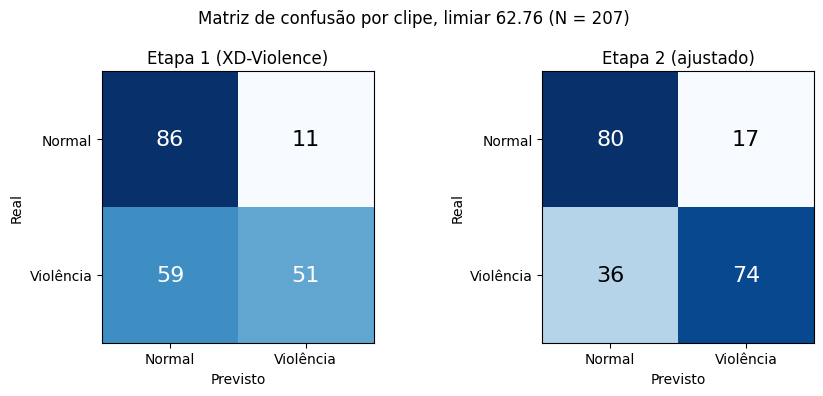

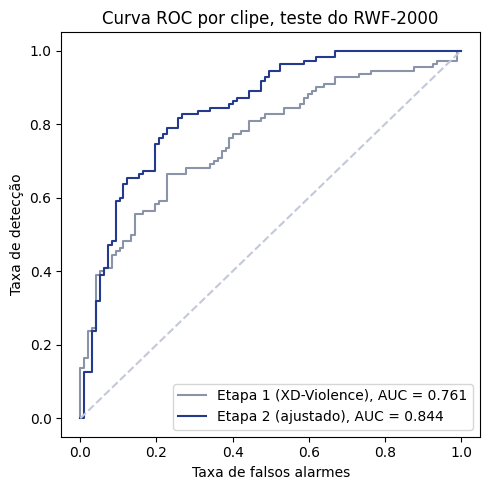

Figuras salvas em /content/drive/MyDrive/safe_evidence_ia/resultados_etapa2


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve

PASTA_FIGURAS = PASTA_BASE / "resultados_etapa2"
PASTA_FIGURAS.mkdir(exist_ok=True)
MODELOS = {"Etapa 1 (XD-Violence)": PESOS_ATUAIS, "Etapa 2 (ajustado)": PESOS_NOVOS}
COR_DAS_CURVAS = {"Etapa 1 (XD-Violence)": "#8a93a8", "Etapa 2 (ajustado)": "#243a8c"}


def pontuar_modelos_no_teste():
    pontuacoes = {}
    for nome, pesos in MODELOS.items():
        pontuacoes[nome], verdadeiros = pontuar_clipes(YOLO(str(pesos)), "test")
    return pontuacoes, verdadeiros


def desenhar_matriz(eixo, verdadeiros, pontuacoes, titulo):
    matriz = confusion_matrix(verdadeiros, pontuacoes >= LIMIAR_ANOMALIA, labels=[False, True])
    eixo.imshow(matriz, cmap="Blues")
    for linha in range(2):
        for coluna in range(2):
            cor = "white" if matriz[linha, coluna] > matriz.max() / 2 else "black"
            eixo.text(coluna, linha, matriz[linha, coluna], ha="center", va="center", fontsize=16, color=cor)
    eixo.set_xticks([0, 1], ["Normal", "Violência"])
    eixo.set_yticks([0, 1], ["Normal", "Violência"])
    eixo.set_xlabel("Previsto")
    eixo.set_ylabel("Real")
    eixo.set_title(titulo)
    return matriz


def salvar_matrizes(pontuacoes, verdadeiros):
    figura, eixos = plt.subplots(1, 2, figsize=(9, 4))
    for eixo, (nome, valores) in zip(eixos, pontuacoes.items()):
        matriz = desenhar_matriz(eixo, verdadeiros, valores, nome)
        vn, fp, fn, vp = matriz.ravel()
        print(f"{nome}: normais certos={vn}, falsos alarmes={fp}, violentos perdidos={fn}, violentos detectados={vp}")
    figura.suptitle(f"Matriz de confusão por clipe, limiar {LIMIAR_ANOMALIA} (N = {len(verdadeiros)})")
    figura.tight_layout()
    figura.savefig(PASTA_FIGURAS / "matriz_confusao_etapa2.png", dpi=200)
    plt.show()


def salvar_curvas_roc(pontuacoes, verdadeiros):
    figura, eixo = plt.subplots(figsize=(5, 5))
    for nome, valores in pontuacoes.items():
        taxa_falso_alarme, taxa_deteccao, _ = roc_curve(verdadeiros, valores)
        area = roc_auc_score(verdadeiros, valores)
        eixo.plot(taxa_falso_alarme, taxa_deteccao, color=COR_DAS_CURVAS[nome], label=f"{nome}, AUC = {area:.3f}")
    eixo.plot([0, 1], [0, 1], "--", color="#c3c9d8")
    eixo.set_xlabel("Taxa de falsos alarmes")
    eixo.set_ylabel("Taxa de detecção")
    eixo.set_title("Curva ROC por clipe, teste do RWF-2000")
    eixo.legend(loc="lower right")
    figura.tight_layout()
    figura.savefig(PASTA_FIGURAS / "curva_roc_etapa2.png", dpi=200)
    plt.show()


pontuacoes_teste, verdadeiros_teste = pontuar_modelos_no_teste()
salvar_matrizes(pontuacoes_teste, verdadeiros_teste)
salvar_curvas_roc(pontuacoes_teste, verdadeiros_teste)
print("Figuras salvas em", PASTA_FIGURAS)

### Continuar treino (só se a sessão caiu)

In [ ]:
# Use só se a sessão caiu durante o treino
ultimo_ponto = PASTA_SAIDA / "ajuste_fino_v4" / "weights" / "last.pt"
YOLO(str(ultimo_ponto)).train(resume=True)
shutil.copy(PASTA_SAIDA / "ajuste_fino_v4" / "weights" / "best.pt", PESOS_NOVOS)

In [ ]:
!pip install -q ultralytics

from google.colab import drive
import subprocess, tempfile
import numpy as np
from pathlib import Path
from ultralytics import YOLO

drive.mount('/content/drive')

PASTA_VIDEOS = Path('/content/drive/MyDrive/safe_evidence_ia/videos-proprios/videos teste')
CAMINHO_MODELO = '/content/drive/MyDrive/safe_evidence_ia/melhor_v4.pt'
EXTENSOES_VIDEO = {'.mp4', '.mov', '.avi'}
CLASSES_POR_PASTA = {'normais': False, 'violentos': True}
QUADROS_POR_SEGUNDO = 4
JANELA_SUAVIZACAO_S = 5
SEGUNDOS_MAIS_CRITICOS = 15
LIMIAR_ANOMALIA = 62.76
LIMIAR_ALERTA_ALTO = 94.24
LARGURA_ESP32CAM, ALTURA_ESP32CAM = 640, 480
TAMANHO_IMAGEM = 224

FILTRO_DE_QUADROS = (
    f'fps={QUADROS_POR_SEGUNDO},'
    f'scale={LARGURA_ESP32CAM}:{ALTURA_ESP32CAM}:force_original_aspect_ratio=decrease,'
    f'pad={LARGURA_ESP32CAM}:{ALTURA_ESP32CAM}:(ow-iw)/2:(oh-ih)/2,'
    f'scale={TAMANHO_IMAGEM}:{TAMANHO_IMAGEM}'
)

modelo = YOLO(CAMINHO_MODELO)
indice_violencia = next(i for i, nome in modelo.names.items() if 'viol' in nome.lower())


def extrair_quadros(caminho_video, pasta_destino):
    subprocess.run(
        ['ffmpeg', '-v', 'error', '-y', '-i', str(caminho_video),
         '-vf', FILTRO_DE_QUADROS, str(pasta_destino / '%05d.jpg')],
        check=True,
    )
    return sorted(pasta_destino.glob('*.jpg'))


def suavizar(probabilidades):
    janela = JANELA_SUAVIZACAO_S * QUADROS_POR_SEGUNDO
    pesos = np.ones(janela)
    somas = np.convolve(probabilidades, pesos, mode='same')
    contagens = np.convolve(np.ones(len(probabilidades)), pesos, mode='same')
    return somas / contagens


def calcular_score(caminho_video):
    with tempfile.TemporaryDirectory() as pasta_temporaria:
        caminhos = extrair_quadros(caminho_video, Path(pasta_temporaria))
        resultados = modelo.predict([str(c) for c in caminhos], imgsz=TAMANHO_IMAGEM, verbose=False, batch=64)
        probabilidades = np.array([r.probs.data[indice_violencia].item() for r in resultados])
    suavizadas = suavizar(probabilidades)
    quantidade = min(len(suavizadas), SEGUNDOS_MAIS_CRITICOS * QUADROS_POR_SEGUNDO)
    return np.sort(suavizadas)[-quantidade:].mean() * 100


def classificar(score):
    if score >= LIMIAR_ALERTA_ALTO:
        return 'Alerta Alto'
    return 'Anomalia' if score >= LIMIAR_ANOMALIA else 'Normal'


resultados_finais = []
for nome_pasta, eh_violento in CLASSES_POR_PASTA.items():
    for video in sorted((PASTA_VIDEOS / nome_pasta).glob('*')):
        if video.suffix.lower() not in EXTENSOES_VIDEO:
            continue
        score = calcular_score(video)
        previsto_violento = score >= LIMIAR_ANOMALIA
        resultados_finais.append((eh_violento, previsto_violento))
        acertou = 'ok' if previsto_violento == eh_violento else 'ERRO'
        print(f'{nome_pasta:10s} {video.name:40s} {score:6.1f}  {classificar(score)}  {acertou}')

acertos = sum(real == previsto for real, previsto in resultados_finais)
print(f'\nAcertos: {acertos} de {len(resultados_finais)}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
normais    esp32cam-01-1057455.mp4                    72.6  Anomalia  ERRO
normais    esp32cam-01-122451.mp4                     58.6  Normal  ok
normais    esp32cam-01-3151163.mp4                    85.6  Anomalia  ERRO
normais    esp32cam-01-31990.mp4                      21.1  Normal  ok
normais    esp32cam-01-3222884.mp4                    67.3  Anomalia  ERRO
normais    esp32cam-01-334764.mp4                     37.4  Normal  ok
normais    esp32cam-01-355964.mp4                     60.5  Normal  ok
normais    esp32cam-01-390558.mp4                     75.2  Anomalia  ERRO


OutOfMemoryError: CUDA out of memory. Tried to allocate 1.17 GiB. GPU 0 has a total capacity of 14.56 GiB of which 1.16 GiB is free. Including non-PyTorch memory, this process has 13.40 GiB memory in use. Of the allocated memory 12.37 GiB is allocated by PyTorch, and 892.01 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

In [ ]:
!pip install -q ultralytics

from google.colab import drive
import gc, subprocess, tempfile
import numpy as np
import torch
from pathlib import Path
from ultralytics import YOLO

drive.mount('/content/drive')

PASTA_VIDEOS = Path('/content/drive/MyDrive/safe_evidence_ia/videos-proprios/videos teste')
CAMINHO_MODELO = '/content/drive/MyDrive/safe_evidence_ia/melhor_v4.pt'
EXTENSOES_VIDEO = {'.mp4', '.mov', '.avi'}
CLASSES_POR_PASTA = {'normais': False, 'violentos': True}
QUADROS_POR_SEGUNDO = 4
JANELA_SUAVIZACAO_S = 5
SEGUNDOS_MAIS_CRITICOS = 15
LIMIAR_ANOMALIA = 62.76
LIMIAR_ALERTA_ALTO = 94.24
LARGURA_ESP32CAM, ALTURA_ESP32CAM = 640, 480
TAMANHO_IMAGEM = 224
TAMANHO_LOTE = 32

FILTRO_DE_QUADROS = (
    f'fps={QUADROS_POR_SEGUNDO},'
    f'scale={LARGURA_ESP32CAM}:{ALTURA_ESP32CAM}:force_original_aspect_ratio=decrease,'
    f'pad={LARGURA_ESP32CAM}:{ALTURA_ESP32CAM}:(ow-iw)/2:(oh-ih)/2,'
    f'scale={TAMANHO_IMAGEM}:{TAMANHO_IMAGEM}'
)

modelo = YOLO(CAMINHO_MODELO)
indice_violencia = next(i for i, nome in modelo.names.items() if 'viol' in nome.lower())


def extrair_quadros(caminho_video, pasta_destino):
    subprocess.run(
        ['ffmpeg', '-v', 'error', '-y', '-i', str(caminho_video),
         '-vf', FILTRO_DE_QUADROS, str(pasta_destino / '%05d.jpg')],
        check=True,
    )
    return sorted(pasta_destino.glob('*.jpg'))


def prever_probabilidades(caminhos):
    probabilidades = []
    for inicio in range(0, len(caminhos), TAMANHO_LOTE):
        lote = [str(c) for c in caminhos[inicio:inicio + TAMANHO_LOTE]]
        for resultado in modelo.predict(lote, imgsz=TAMANHO_IMAGEM, verbose=False):
            probabilidades.append(resultado.probs.data[indice_violencia].item())
    return np.array(probabilidades)


def suavizar(probabilidades):
    janela = JANELA_SUAVIZACAO_S * QUADROS_POR_SEGUNDO
    pesos = np.ones(janela)
    somas = np.convolve(probabilidades, pesos, mode='same')
    contagens = np.convolve(np.ones(len(probabilidades)), pesos, mode='same')
    return somas / contagens


def calcular_score(caminho_video):
    with tempfile.TemporaryDirectory() as pasta_temporaria:
        caminhos = extrair_quadros(caminho_video, Path(pasta_temporaria))
        probabilidades = prever_probabilidades(caminhos)
    suavizadas = suavizar(probabilidades)
    quantidade = min(len(suavizadas), SEGUNDOS_MAIS_CRITICOS * QUADROS_POR_SEGUNDO)
    return np.sort(suavizadas)[-quantidade:].mean() * 100


def classificar(score):
    if score >= LIMIAR_ALERTA_ALTO:
        return 'Alerta Alto'
    return 'Anomalia' if score >= LIMIAR_ANOMALIA else 'Normal'


def liberar_memoria_da_gpu():
    gc.collect()
    torch.cuda.empty_cache()


resultados_finais = []
for nome_pasta, eh_violento in CLASSES_POR_PASTA.items():
    for video in sorted((PASTA_VIDEOS / nome_pasta).glob('*')):
        if video.suffix.lower() not in EXTENSOES_VIDEO:
            continue
        score = calcular_score(video)
        liberar_memoria_da_gpu()
        previsto_violento = score >= LIMIAR_ANOMALIA
        resultados_finais.append((eh_violento, previsto_violento))
        acertou = 'ok' if previsto_violento == eh_violento else 'ERRO'
        print(f'{nome_pasta:10s} {video.name:40s} {score:6.1f}  {classificar(score)}  {acertou}')

acertos = sum(real == previsto for real, previsto in resultados_finais)
print(f'\nAcertos: {acertos} de {len(resultados_finais)}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
normais    esp32cam-01-1057455.mp4                    72.6  Anomalia  ERRO
normais    esp32cam-01-122451.mp4                     58.6  Normal  ok
normais    esp32cam-01-3151163.mp4                    85.6  Anomalia  ERRO
normais    esp32cam-01-31990.mp4                      21.1  Normal  ok
normais    esp32cam-01-3222884.mp4                    67.3  Anomalia  ERRO
normais    esp32cam-01-334764.mp4                     37.4  Normal  ok
normais    esp32cam-01-355964.mp4                     60.5  Normal  ok
normais    esp32cam-01-390558.mp4                     75.2  Anomalia  ERRO
normais    esp32cam-01-4798466.mp4                    94.8  Alerta Alto  ERRO
normais    esp32cam-01-486253.mp4                     96.3  Alerta Alto  ERRO
normais    esp32cam-01-596157.mp4                     81.7  Anomalia  ERRO
normais    esp32cam-01-75390.mp4                      82

In [ ]:
!md5sum /content/drive/MyDrive/safe_evidence_ia/*.pt


809620c93481a5300c2dc5a1fe7974eb  /content/drive/MyDrive/safe_evidence_ia/melhor.pt
ad4d65638c3d97b94ea78f2038974552  /content/drive/MyDrive/safe_evidence_ia/melhor_v2.pt
76dbf914da9a2e03aba88c64d46e2dbd  /content/drive/MyDrive/safe_evidence_ia/melhor_v3.pt
d3fd6ca190fa2ceabc4375e3d5e71ebe  /content/drive/MyDrive/safe_evidence_ia/melhor_v4.pt
